# Effective fluorescence polarization of a live T-cell membrane


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：polcam_fluorescence_orientation

**观测 y：** intensity(1, 116, 298, 298)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 有效Stokes、角度和偏振度空间场。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 四分析器强度线性关系I=A S。本地路径为 `solvers.reconstruct→estimate_stokes`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 2, 4, 6, 8, 10, 12（cell编号按文件内从0计）。章节包括：# Effective fluorescence polarization of a live T-cell membrane；Raw observations and the four physically assigned analyzer channels. The displayed plane is selected by maximum fresh Stokes-intensity sum, a display choice only. All planes are reconstructed and scored.；Fresh Stokes field, degree and pi-periodic orientation. Angle color is interpreted with polarized signal strength: weak anisotropy does not justify a confident molecular axis.；The stack and orthogonal detector sections retain acquisition index along the axial axis. Published nominal lateral pitch is available, but conflicting deposited metadata do not justify assigning physical z distances. This is a stack of effective optical sections, not a recovered local 3D orientation tensor.；Observed analyzer residuals and plane-level statistics. The residual exposes the approximation of four neighboring detector samples by one common field. Per-plane upstream/local errors are computed from freshly reconstructed arrays, not substituted archived values.；Sensitivity experiments are freshly recomputed on the same measurements. A uniform detector pedestal changes degree but cancels from the signed linear Stokes components and orientation; spatial averaging reduces fluctuations while mixing local orientations. These comparisons leave the canonical zero-offset, unsmoothed reconstruction intact.；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 2×2超像素有效偏振，无生物方向GT；强度stack不是GT。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


This notebook actively reconstructs the complete author-deposited NR4A EPI stack. It follows the diffraction-limited POLCAM analyzer inverse, rather than the paper's separate single-molecule/3D dipole fitting experiments. Raw analyzer pixels sample neighboring positions. We retain one effective superpixel per 2 by 2 detector tile and all 116 planes.

The unknown Stokes field is $S=(S_0,S_1,S_2)$ in ADU. The analyzer law is $I_0=(S_0+S_1)/2$, $I_{45}=(S_0+S_2)/2$, $I_{90}=(S_0-S_1)/2$, $I_{135}=(S_0-S_2)/2$. Least squares gives $S_0=\sum I/2$, $S_1=I_0-I_{90}$ and $S_2=I_{45}-I_{135}$. The effective angle is $\phi=\operatorname{atan2}(S_2,S_1)/2$; degree $p=\sqrt{S_1^2+S_2^2}/|S_0|$. These are detector quantities with nominal zero-offset, not an absolute molecular tilt/wobble measurement.

The published paper (Bruggeman et al., Nature Methods 2024, DOI 10.1038/s41592-024-02382-8), the exact source revision and the data transformation are indexed in `test/validation.md`. The unmodified upstream run and the fresh cleaned result have distinct provenance. The hidden baseline is a method reconstruction, not biological truth.

## 2. Data

`data/raw_data.npz` is a lossless array conversion of all pixels and planes of the author's deposited EPI stack. Small acquisition conventions are specified below.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| intensity | (1, 116, 298, 298) | uint16 | Original polarization-mosaic intensities in camera ADU; axes batch, acquired plane, raw detector row, raw detector column. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Specimen | Live J8 LFA-1 T cell, NR4A membrane label | dimensionless | Single deposited EPI stack |
| Illumination | EPI, 515 | nm | Excitation wavelength, randomized excitation polarization through multimode fiber |
| Excitation density | approximately 0.004 | kW/cm^2 | Author-reported image-plane power density |
| Camera | Thorlabs CS505MUP | dimensionless | Four-direction micropolarizer array |
| Detector pitch | 3.45 | micrometer | Physical sensor pixel pitch; no resampling is applied |
| Nominal system magnification | 50 | dimensionless | Published microscope 3 has 100x objective with 2x demagnification |
| Nominal sample-plane raw pitch | 69 | nm | Published microscope 3 optical scale; crop origin remains unspecified |
| Effective lateral spacing | 138 | nm | Two raw pixels per reconstructed superpixel |
| Objective | 100x, NA 1.49, oil immersion | dimensionless | Published microscope 3 setup |
| Exposure | 500.004 | ms | Acquisition metadata exposure |
| Mosaic | [-45, 0; 90, 45] | degree | Within each 2 by 2 raw detector tile, row-major order |
| Nominal detector offset | 0.0 | ADU | Effective uncorrected detector convention; not a measured physical black level |
| Gain | Not registered to deposited crop | unavailable | Preserve ADU; no conversion to photon counts |
| Noise | Measured, variance not calibrated for this crop | ADU | No synthetic noise is added |
| Deposited stack | 116 by 298 by 298 | plane/pixel/pixel | All released pixels and all acquired planes are retained |
| Axial coordinate | Acquired plane index 0 through 115 | index | Retain ordering; deposited axial step and absolute position are not reliably specified |
| Boundary | Independent 2 by 2 tiles | dimensionless | No wrapping, interpolation or spatial extrapolation |
| Coordinate convention | Columns right, rows down | raw detector pixel | Origin is top-left of the deposited crop |

The associated acquisition metadata describe a larger 644 by 644 camera region while the deposited TIFF is 298 by 298. The post-acquisition crop offset is unspecified. The image array and its plane order are authoritative; do not infer a full-sensor crop origin or physical axial spacing from the incompatible metadata. Nominal lateral optical scale is given for interpretation and does not alter the detector-coordinate inverse.

## 3. Physics

At one effective 2 by 2 detector tile the four analyzer intensities obey $I_\alpha=(S_0+S_1\cos2\alpha+S_2\sin2\alpha)/2$, with angles $\alpha=0,45,90,135$ degrees. $I$ and $S$ use ADU. Neighboring analyzer pixels are modeled as one field, an approximation that can leave residual even at the least-squares optimum. This does not encode axial dipole tilt or circular Stokes polarization.

## 4. Method

### Evaluation of fresh arrays

All Stokes components and polarization degree are checked separately using cosine NCC and dynamic-range NRMSE. The angle is pi-periodic and weighted by fixed upstream polarized intensity squared because isotropic pixels have no identifiable direction. Forward residual measures the mismatch between all four measured channels and the three-component analyzer model; a nonzero residual is expected from noise and interlaced spatial sampling. No scale, crop or registration is optimized.

Convert the full uint16 `(1,116,298,298)` stack to float64 before summing/differencing. Assign analyzer channels by the declared parity pattern, then evaluate

$$
S_0=\tfrac12\sum_\alpha I_\alpha,\quad S_1=I_0-I_{90},\quad S_2=I_{45}-I_{135}.
$$

The effective angle is $\phi=\operatorname{atan2}(S_2,S_1)/2$ radians and degree is $p=\operatorname{hypot}(S_1,S_2)/|S_0|$. No interpolation, clipping or learned inverse is used. Weak polarized intensity makes angle poorly identifiable, motivating the fixed polarized-intensity weighting in evaluation rather than treating every pixel equally.

## 5. Results




In [1]:
%matplotlib inline
from pathlib import Path
import os,time,json,sys,importlib.util
root=Path.cwd()
if root.name=='notebooks': root=root.parent
assert (root/'data/raw_data.npz').exists()
os.chdir(root)
sys.path.insert(0,str(root))
import numpy as np
from IPython.display import display
from src.main import run
from src.preprocessing import load_observations
from src.visualization import make_figures
started=time.perf_counter()
fresh=run()
runtime=time.perf_counter()-started
raw=load_observations()
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:
    upstream={k:f[k] for k in fresh}
print('Fresh reconstruction runtime (s):',runtime)
print('Bound raw stack:',raw.shape,raw.dtype)
print('No target/hidden reference was read by src.main.run.')
provenance=json.loads(Path('notebooks/reference_outputs/measurements.json').read_text(encoding='utf8'))
print('Measurement provenance:',provenance['source_categories'])

Fresh reconstruction runtime (s): 4.2494560000050114
Bound raw stack: (1, 116, 298, 298) uint16
No target/hidden reference was read by src.main.run.
Measurement provenance: {'paper_report': 'Published Fig.6 illustrates other processed representations; no reported historical numerical accuracy is used here.', 'reproduced_upstream': 'Full exact bound stack, unmodified napari-polcam e4cd20f39b6b726ade8e17a4768f2210596e612d; None method, offset0; arrays in evaluation/baseline_reference.npz', 'fresh_cleaned': 'Actively reconstructed by src.main.run; arrays in output/reconstruction.npz'}


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "stokes0_ncc": 1.0000000000000002,
    "stokes0_nrmse": 0.0,
    "stokes1_ncc": 1.0000000000000002,
    "stokes1_nrmse": 0.0,
    "stokes2_ncc": 1.0,
    "stokes2_nrmse": 0.0,
    "degree_ncc": 1.0,
    "degree_nrmse": 1.3773962485057759e-17,
    "angular_rmse": 0.0,
    "observation_residual": 0.016804278834125018
  },
  "thresholds": {
    "stokes0_ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "stokes0_nrmse": {
      "comparison": "<=",
      "boundary": 1e-10
    },
    "stokes1_ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "stokes1_nrmse": {
      "comparison": "<=",
      "boundary": 1e-10
    },
    "stokes2_ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "stokes2_nrmse": {
      "comparison": "<=",
      "boundary": 1e-10
    },
    "degree_ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "degree_nrmse": {


{
  "display_plane_index": 111,
  "canonical_offset_ADU": 0.0,
  "nominal_lateral_superpixel_nm": 138.0,
  "reconstruction_ncc": 0.9999999999999998,
  "reconstruction_dynamic_range_nrmse": 0.0,
  "degree_ncc": 1.0,
  "degree_dynamic_range_nrmse": 1.3773962485057759e-17,
  "orientation_weighted_periodic_rmse_rad": 0.0,
  "observation_relative_residual": 0.016804278834125018,
  "max_offset_angle_change_rad": 0.0,
  "display_mean_degree_by_offset": {
    "0": 0.036756332396378204,
    "50": 0.039799940434441336,
    "100": 0.0434042700908827,
    "150": 0.047743919045052624
  }
}


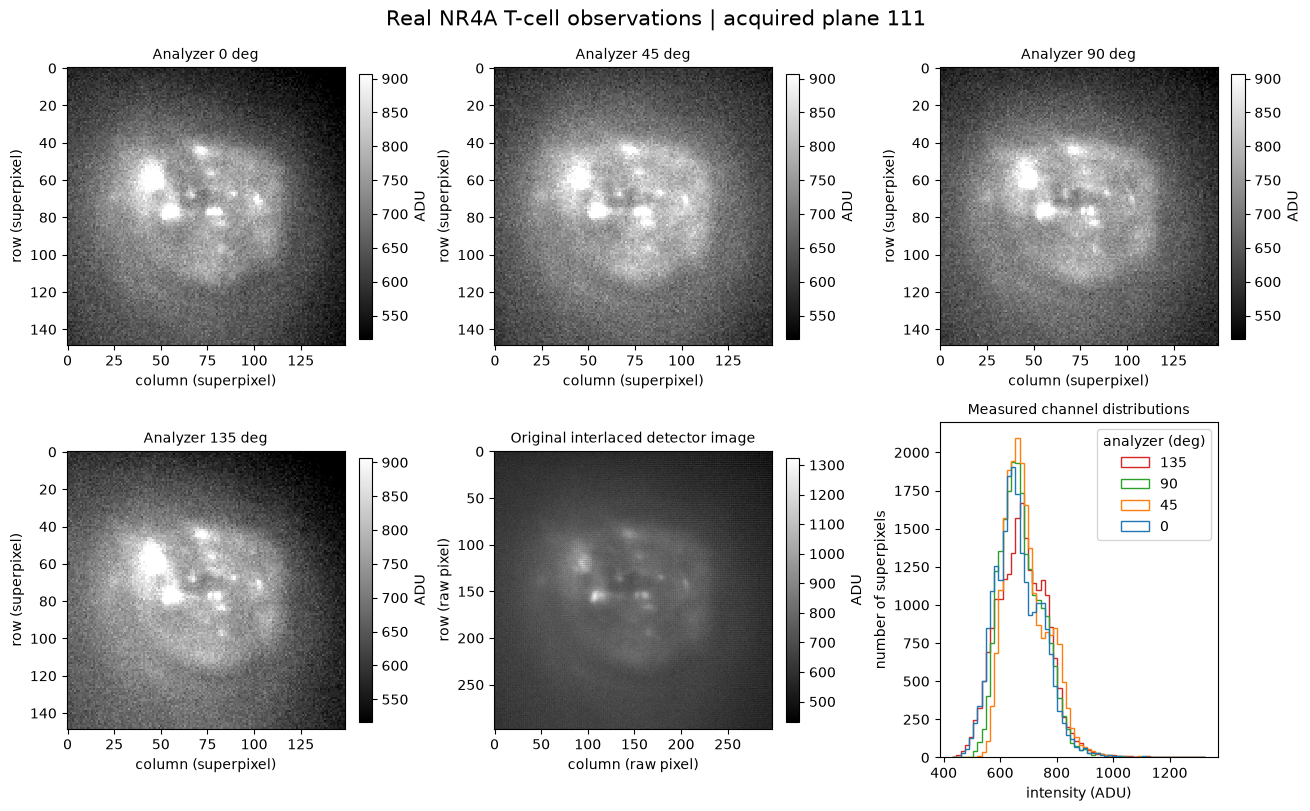

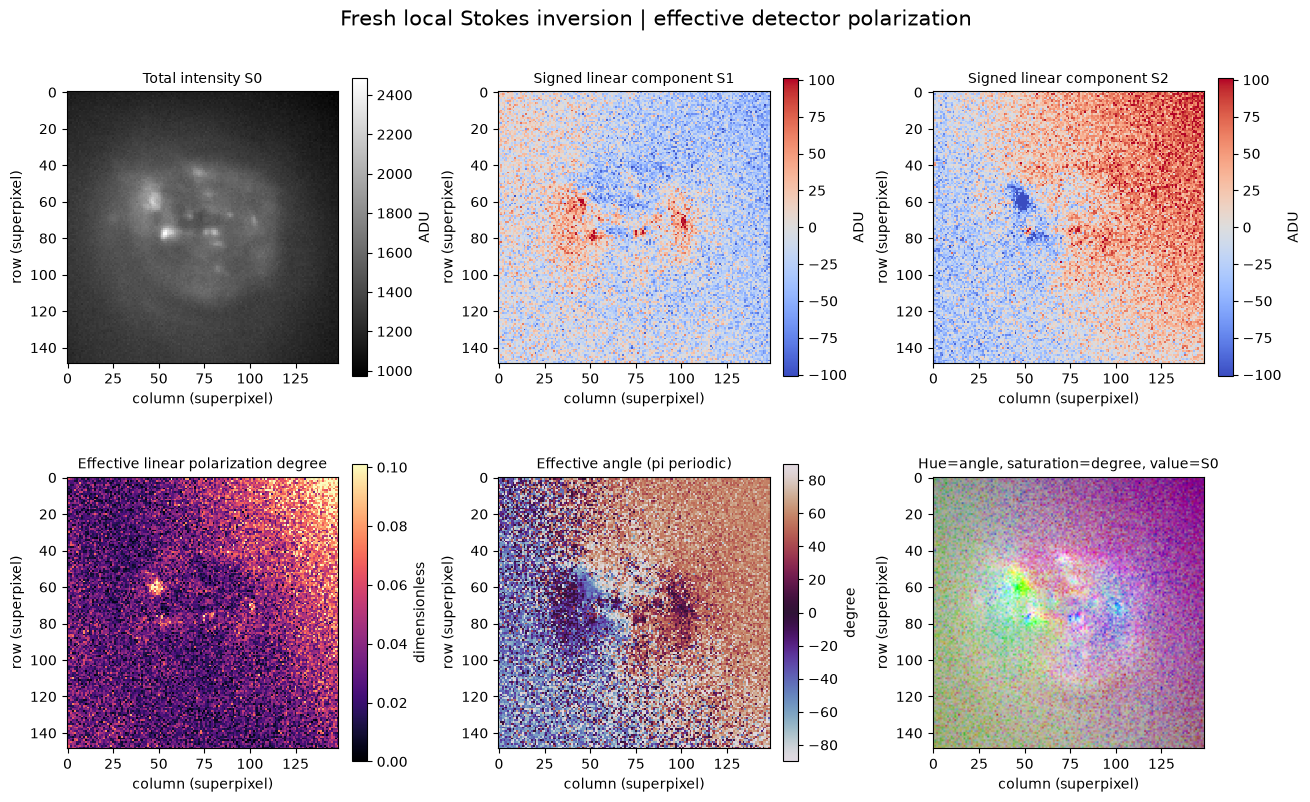

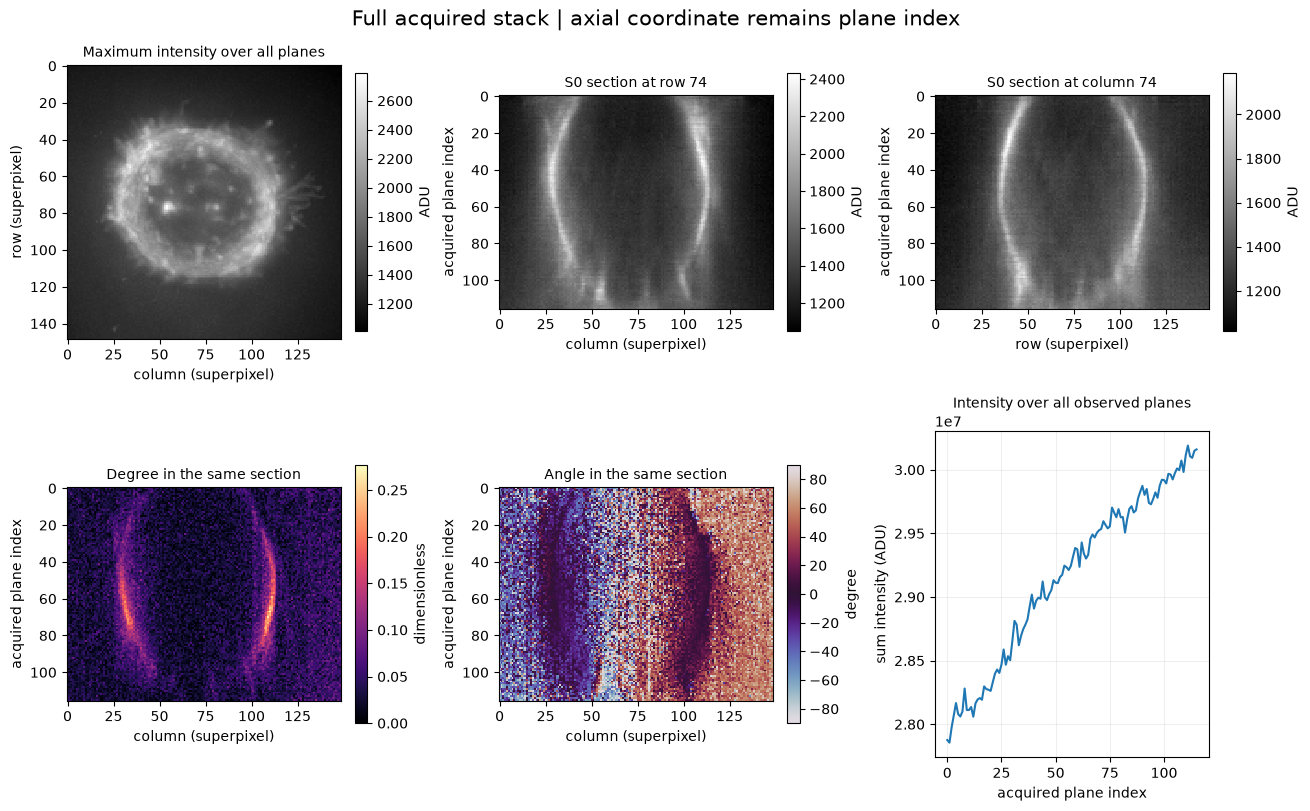

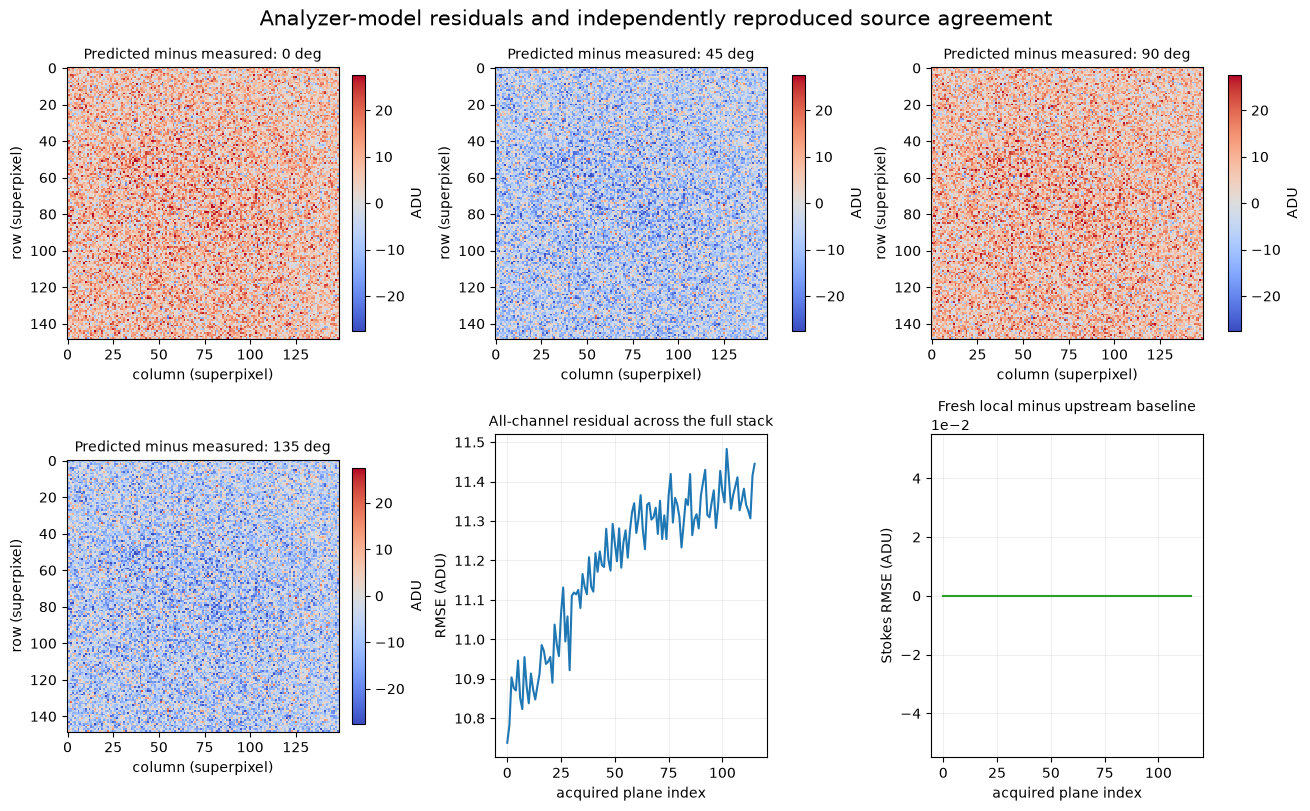

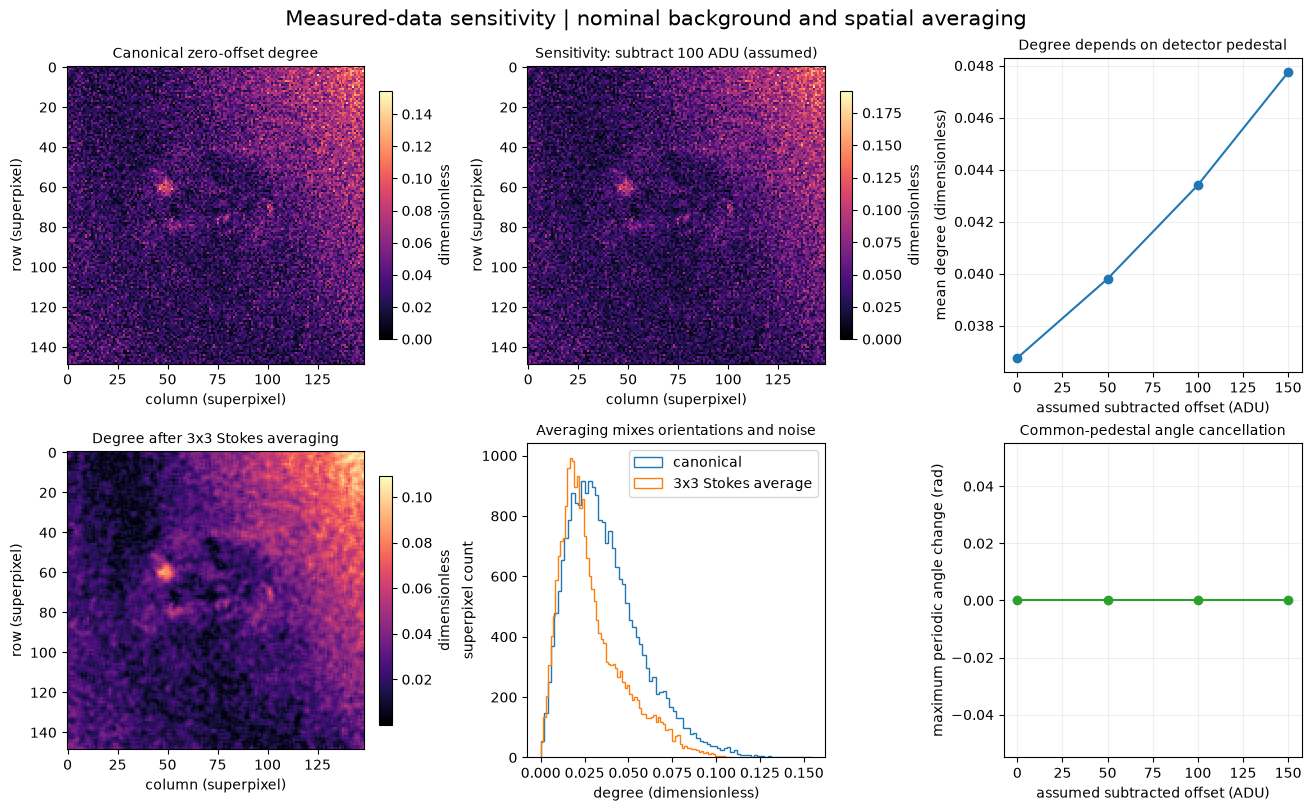

In [2]:
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(root/'output/reconstruction.npz')
print(json.dumps(report,indent=2))
assert exit_code==0
figures,numeric,measurements=make_figures(raw,fresh,upstream)
print(json.dumps(measurements,indent=2))

Raw observations and the four physically assigned analyzer channels. The displayed plane is selected by maximum fresh Stokes-intensity sum, a display choice only. All planes are reconstructed and scored.


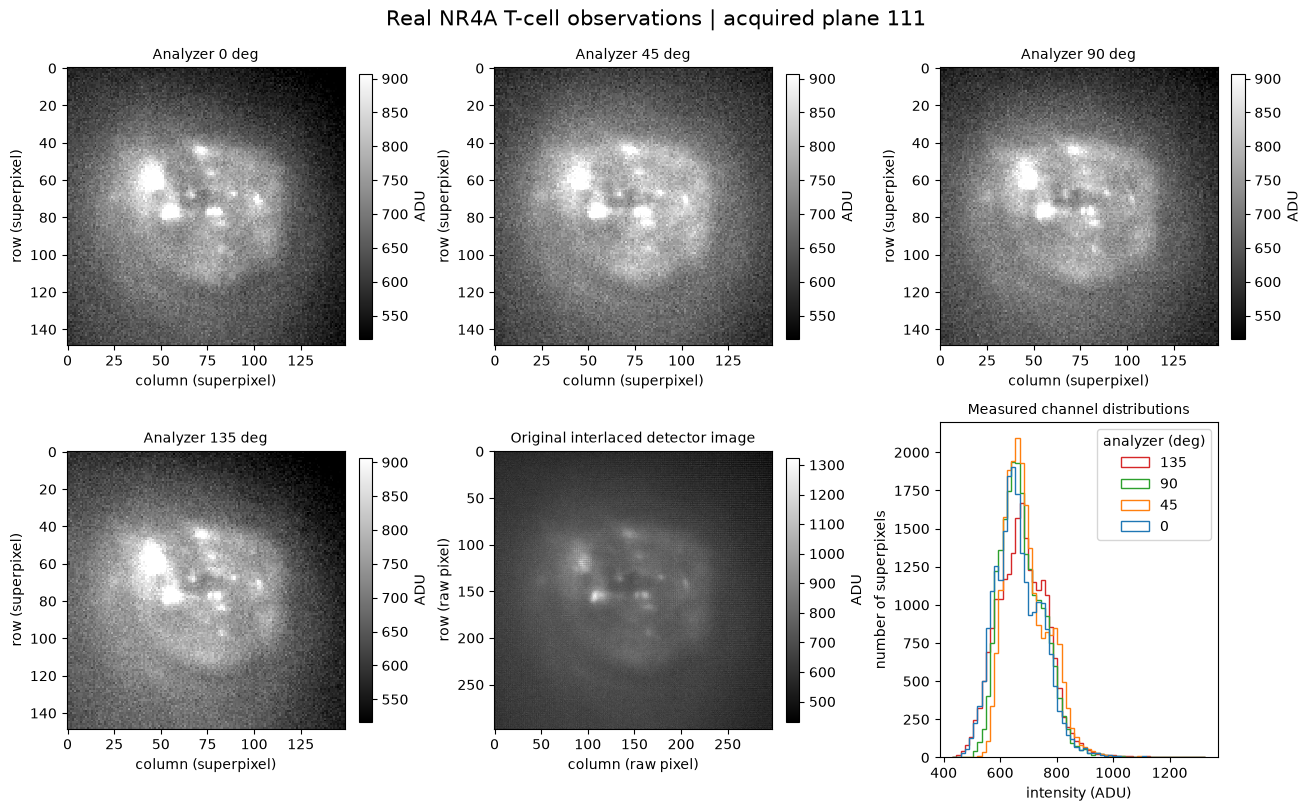

In [3]:
display(figures[0])

Fresh Stokes field, degree and pi-periodic orientation. Angle color is interpreted with polarized signal strength: weak anisotropy does not justify a confident molecular axis.


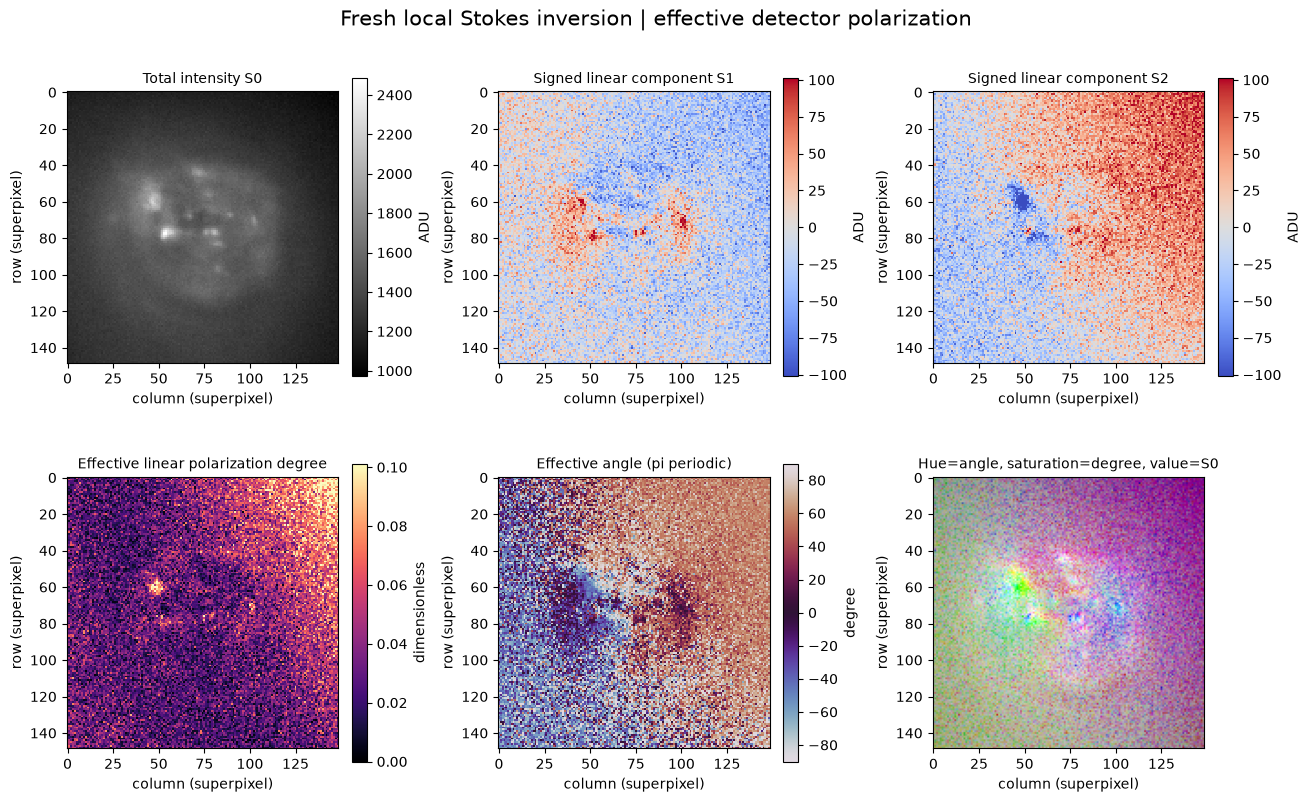

In [4]:
display(figures[1])

The stack and orthogonal detector sections retain acquisition index along the axial axis. Published nominal lateral pitch is available, but conflicting deposited metadata do not justify assigning physical z distances. This is a stack of effective optical sections, not a recovered local 3D orientation tensor.


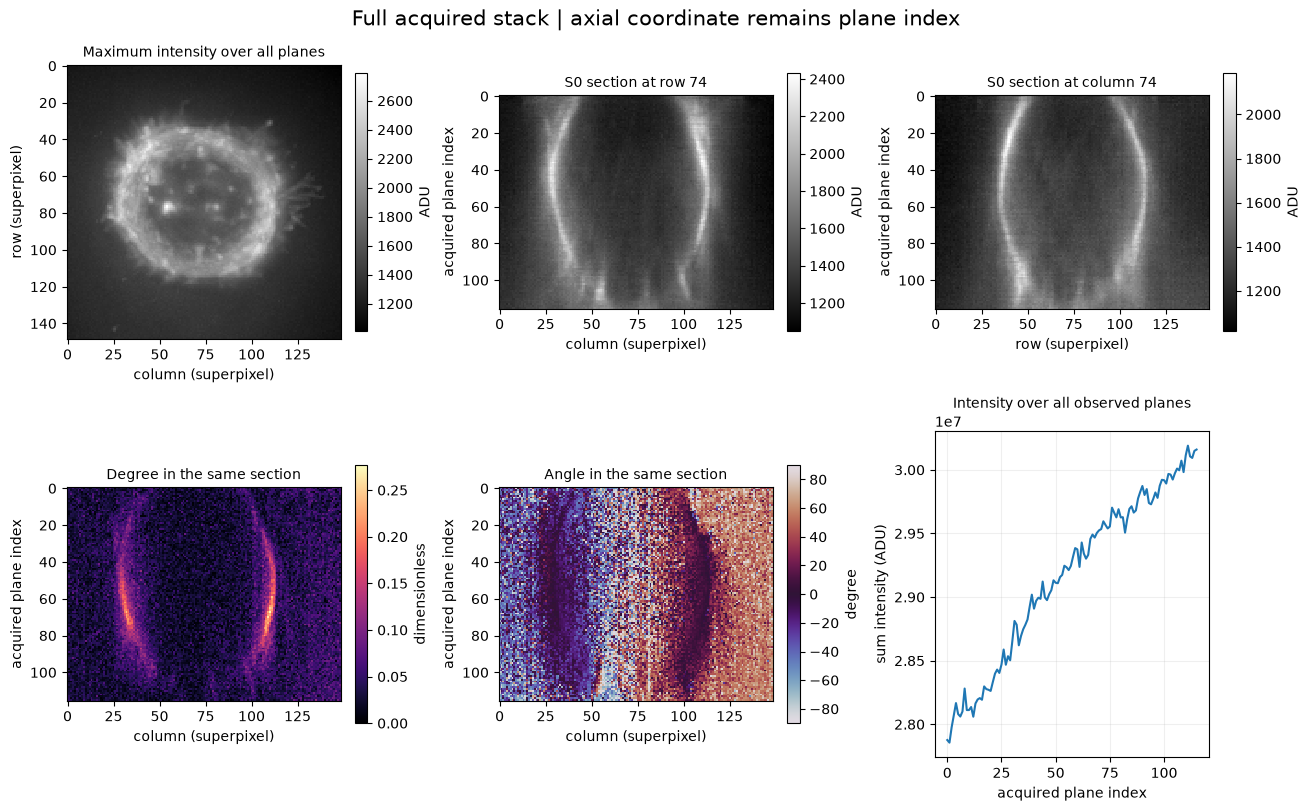

In [5]:
display(figures[2])

Observed analyzer residuals and plane-level statistics. The residual exposes the approximation of four neighboring detector samples by one common field. Per-plane upstream/local errors are computed from freshly reconstructed arrays, not substituted archived values.


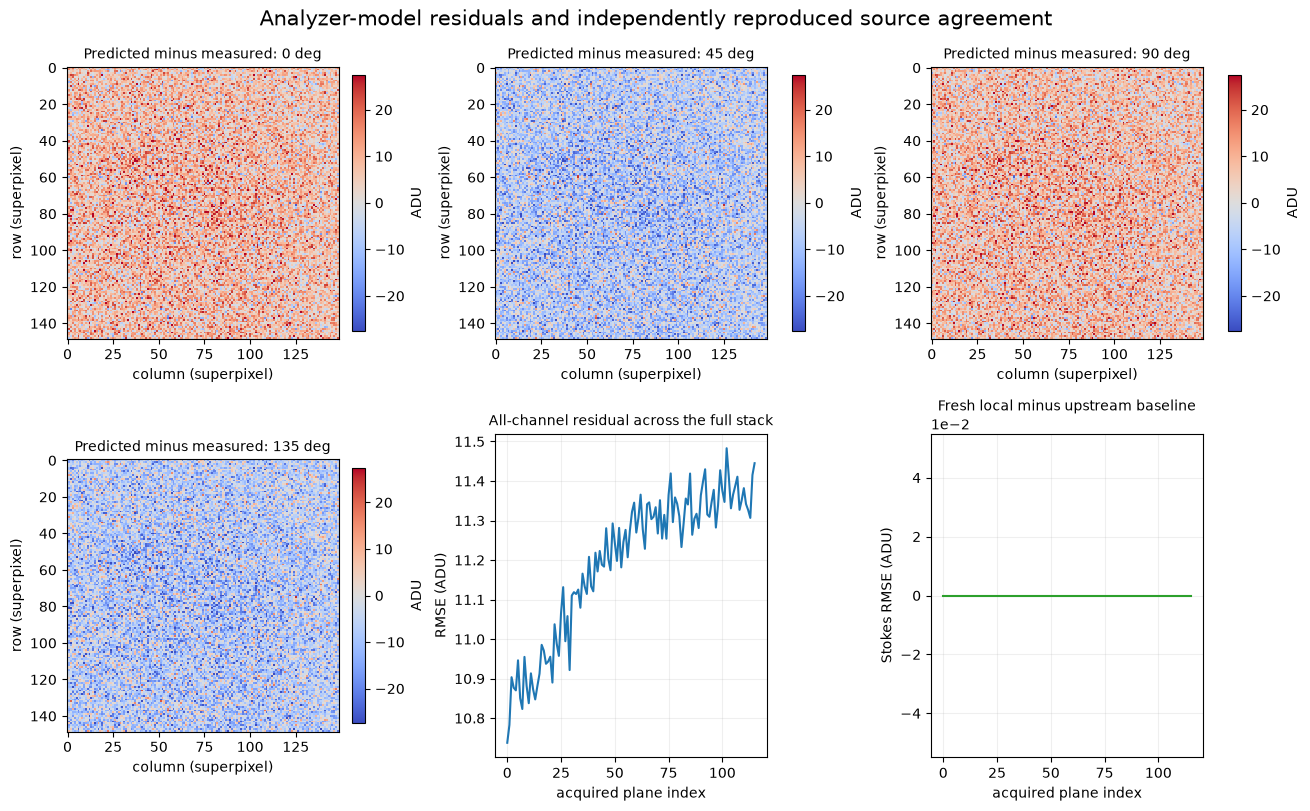

In [6]:
display(figures[3])

Sensitivity experiments are freshly recomputed on the same measurements. A uniform detector pedestal changes degree but cancels from the signed linear Stokes components and orientation; spatial averaging reduces fluctuations while mixing local orientations. These comparisons leave the canonical zero-offset, unsmoothed reconstruction intact.


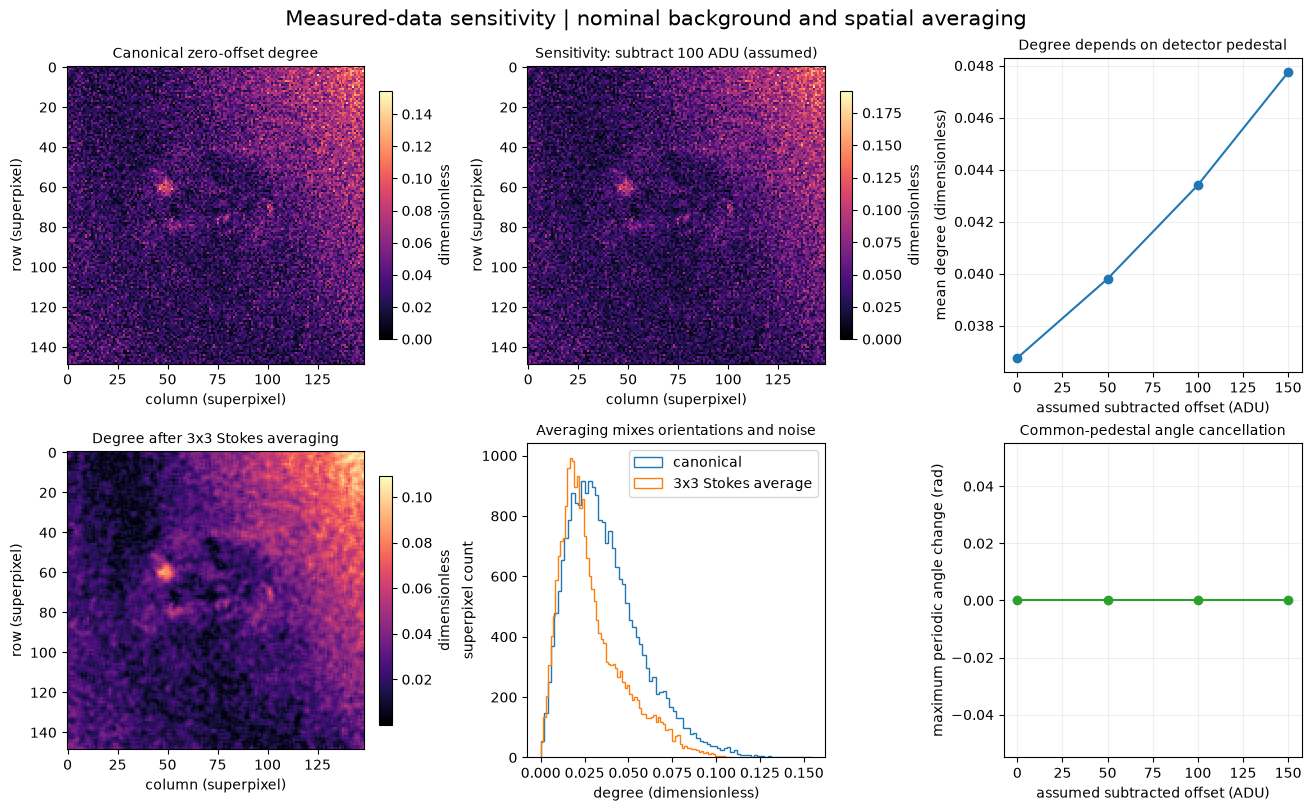

In [7]:
display(figures[4])

## 6. Conclusion

### Interpretation and limitations

The complete real stack is reconstructed and agrees numerically with the independently executed source estimator. The detector-analyzer residual quantifies a real model mismatch; agreement with a baseline does not establish molecular truth. The acquisition contains no independent orientation truth, no registered per-pixel calibration for the published crop, and unreliable physical z coordinates. Therefore effective AoLP/DoLP can describe relative polarization organization but must not be relabeled as calibrated 3D molecular orientation, absolute rotational mobility, photon density or membrane thickness.

The comparison scope matches this single diffraction-limited EPI acquisition. The paper's other specimen groups, single-molecule simulations, DSF fitting and live time-lapse datasets require different measurements and are not claimed reproduced here.
